In [93]:
import geopandas as gpd
import rasterio
import pandas as pd

In [94]:
pop_tanzania = rasterio.open('../tza_pop_2026_CN_1km_R2025A_UA_v1.tif')

In [95]:
pd.DataFrame(pop_tanzania.dataset_mask().flatten())[0].unique()

array([  0, 255], dtype=uint8)

In [96]:
import numpy as np

# Read population values from band 1, masking NoData pixels.
population = pop_tanzania.read(1, masked=True)
rows, cols = np.where(~np.ma.getmaskarray(population))
x, y = rasterio.transform.xy(pop_tanzania.transform, rows, cols, offset="center")

# Coordinates use the TIFF's CRS (see pop_tanzania.crs).
population_df = pd.DataFrame({
    "x": x,
    "y": y,
    "population": population.data[rows, cols],
})

population_df.head()


,x,y,population
0,30.76249916,-0.98749966,142.38700867
1,30.77083249,-0.98749966,18.80851746
2,30.75416582,-0.99583299,40.08856964
3,30.76249916,-0.99583299,95.12718964
4,30.77083249,-0.99583299,25.02785110


In [97]:
from pathlib import Path

from scipy import sparse
from sklearn.pipeline import Pipeline
from water_wells import (
    DataConfig, DataLoader, DataPreprocessor, FeatureEngineer, TrainingConfig,
)

# Support running Jupyter from either the project root or notebooks/.
project_root = Path.cwd()
if not (project_root / "pyproject.toml").exists():
    project_root = project_root.parent

# The loader reads the two root CSVs and aligns labels by well ID.
X_raw, y = DataLoader(DataConfig(data_dir=project_root)).load_training()
config = TrainingConfig()

# Reuse the same feature/preprocessing steps as TrainingPipeline, without a model.
preprocessing_pipeline = Pipeline([
    ("features", FeatureEngineer()),
    ("preprocessing", DataPreprocessor(config.min_frequency, config.max_categories)),
])
X_preprocessed = preprocessing_pipeline.fit_transform(X_raw, y)

# Readable features for filtering, plotting, and geographic exploration.
training_df = preprocessing_pipeline.named_steps["features"].transform(X_raw)
training_df.insert(0, "id", X_raw["id"])
training_df["status_group"] = y

# Fully preprocessed model features; sparse columns avoid a large dense copy.
feature_names = preprocessing_pipeline.named_steps["preprocessing"].get_feature_names_out()
if sparse.issparse(X_preprocessed):
    preprocessed_df = pd.DataFrame.sparse.from_spmatrix(
        X_preprocessed, index=X_raw.index, columns=feature_names,
    )
else:
    preprocessed_df = pd.DataFrame(
        X_preprocessed, index=X_raw.index, columns=feature_names,
    )
preprocessed_df.insert(0, "id", X_raw["id"])
preprocessed_df["status_group"] = y

# Full-data preprocessing is for exploration; split raw rows first for evaluation.
print(f"Readable: {training_df.shape}; preprocessed: {preprocessed_df.shape}")
training_df.head()


Readable: (59400, 45); preprocessed: (59400, 492)


,id,amount_tsh,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,source_class,waterpoint_type,waterpoint_type_group,nearby_wells_3km,nearby_wells_5km,nearby_wells_10km,nearby_wells_20km,well_age,construction_year_missing,status_group
0,69572,6000.00000000,Roman,1390,Roman,34.93809275,-9.85632177,none,0,Lake Nyasa,...,groundwater,communal standpipe,communal standpipe,18.00000000,18.00000000,29.00000000,91.00000000,12.00000000,0,functional
1,8776,0.00000000,Grumeti,1399,GRUMETI,34.69876610,-2.14746569,Zahanati,0,Lake Victoria,...,surface,communal standpipe,communal standpipe,26.00000000,28.00000000,29.00000000,31.00000000,3.00000000,0,functional
2,34310,25.00000000,Lottery Club,686,World vision,37.46066446,-3.82132853,Kwa Mahundi,0,Pangani,...,surface,communal standpipe multiple,communal standpipe,16.00000000,16.00000000,18.00000000,106.00000000,4.00000000,0,functional
3,67743,0.00000000,Unicef,263,UNICEF,38.48616088,-11.15529772,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,...,groundwater,communal standpipe multiple,communal standpipe,12.00000000,17.00000000,29.00000000,53.00000000,27.00000000,0,non functional
4,19728,0.00000000,Action In A,0,Artisan,31.13084671,-1.82535885,Shuleni,0,Lake Victoria,...,surface,communal standpipe,communal standpipe,8.00000000,18.00000000,47.00000000,156.00000000,NaN,1,functional


In [98]:
training_df.isna().sum()

id                               0
amount_tsh                       0
funder                        3637
gps_height                       0
installer                     3655
longitude                        0
latitude                         0
wpt_name                         0
num_private                      0
basin                            0
region                           0
region_code                      0
district_code                    0
lga                              0
ward                             0
population                       0
public_meeting                3334
recorded_by                      0
scheme_management             3878
scheme_name                  28810
permit                        3056
construction_year            20709
extraction_type                  0
extraction_type_group            0
extraction_type_class            0
management                       0
management_group                 0
payment                          0
payment_type        

In [99]:
preprocessed_df


,id,funder__funder_0,funder__funder_Adb,funder__funder_Adra,funder__funder_Amref,funder__funder_Ces(gmbh),funder__funder_Danida,funder__funder_Ded,funder__funder_Dh,funder__funder_Dhv,...,numerical__district_code,numerical__population,numerical__construction_year,numerical__nearby_wells_3km,numerical__nearby_wells_5km,numerical__nearby_wells_10km,numerical__nearby_wells_20km,numerical__well_age,numerical__construction_year_missing,status_group
0,69572,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,5.00000000,109.00000000,1999.00000000,18.00000000,18.00000000,29.00000000,91.00000000,12.00000000,0.00000000,functional
1,8776,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,2.00000000,280.00000000,2010.00000000,26.00000000,28.00000000,29.00000000,31.00000000,3.00000000,0.00000000,functional
2,34310,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,4.00000000,250.00000000,2009.00000000,16.00000000,16.00000000,18.00000000,106.00000000,4.00000000,0.00000000,functional
3,67743,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,63.00000000,58.00000000,1986.00000000,12.00000000,17.00000000,29.00000000,53.00000000,27.00000000,0.00000000,non functional
4,19728,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,1.00000000,0.00000000,NaN,8.00000000,18.00000000,47.00000000,156.00000000,NaN,1.00000000,functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59395,60739,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,5.00000000,125.00000000,1999.00000000,59.00000000,179.00000000,574.00000000,1235.00000000,14.00000000,0.00000000,functional
59396,27263,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,4.00000000,56.00000000,1996.00000000,16.00000000,22.00000000,22.00000000,62.00000000,15.00000000,0.00000000,functional
59397,37057,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,7.00000000,0.00000000,NaN,2.00000000,3.00000000,19.00000000,204.00000000,NaN,1.00000000,functional
59398,31282,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,...,4.00000000,0.00000000,NaN,9.00000000,32.00000000,55.00000000,156.00000000,NaN,1.00000000,functional


In [100]:
population_df.head()


,x,y,population
0,30.76249916,-0.98749966,142.38700867
1,30.77083249,-0.98749966,18.80851746
2,30.75416582,-0.99583299,40.08856964
3,30.76249916,-0.99583299,95.12718964
4,30.77083249,-0.99583299,25.02785110


In [101]:
from pathlib import Path
from water_wells import TrainingPipeline, POPULATION_COLUMNS

root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent

# Reuse the shared pipeline implementation and persistent population cache.
population_data_pipeline = TrainingPipeline(
    population_raster=root / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif",
    cache_dir=root / "data/processed/population",
    data_mode="auto",  # use "load" to forbid calculation on cache misses
)
training_df = population_data_pipeline.prepare_population_data(
    training_df,
    output_path=root / "data/processed/training_population_exploration.csv",
)
radius_columns = POPULATION_COLUMNS
training_df[["id", "population", *radius_columns.values()]].head()


,id,population,Population_1km,Population_2km,Population_3km,population_5km,population_10km,population_20km
0,69572,109,956.50975037,1542.20597315,1955.47935033,2588.41721980,6063.17276794,20983.92246772
1,8776,280,563.68610382,1692.84684564,2704.02426021,3565.20580255,4922.41481817,6793.85244612
2,34310,250,5265.04971266,5817.32178760,7392.55767262,9522.88976526,16132.29245451,49572.23166046
3,67743,58,943.30356252,2292.34552133,3668.81828344,8637.31050903,16060.10057172,39220.54397569
4,19728,0,1635.06237793,3825.14646149,8420.76175690,16413.22319460,43751.88580873,128244.52853138


In [102]:
pd.set_option('display.float_format', '{:.8f}'.format)

In [103]:
training_df.groupby(['latitude', 'longitude', 'population'])[['population_10km']].mean().reset_index().sort_values(by='population_10km').tail(600)

,latitude,longitude,population,population_10km
43632,-3.35341605,36.68387456,200,930228.30771200
43602,-3.35434536,36.69054976,200,930917.89658552
43485,-3.35811482,36.67331251,200,930927.16659026
43592,-3.35474838,36.69774981,200,931153.02488279
52563,-2.49645868,32.98478963,0,933041.22240829
...,...,...,...,...
21531,-6.89757912,39.21283461,250,2734865.26590568
21483,-6.90059583,39.21474861,80,2738851.04378349
21545,-6.89636320,39.21403003,300,2747130.48477775
21549,-6.89593450,39.21448429,148,2747452.35489494


In [104]:
population_df['population'].sum()

np.float32(7.1549624e+07)

In [105]:
from pathlib import Path
from IPython.display import display
from water_wells import DataConfig, DataLoader, TrainingConfig, TrainingPipeline, ModelEvaluator

population_features = [
    "Population_1km", "Population_2km", "Population_3km",
    "population_5km", "population_10km", "population_20km",
]

# Population features are now generated and cached by the pipeline.
root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent
X_raw, y_model = DataLoader(DataConfig(data_dir=root)).load_training()
population_pipeline = TrainingPipeline(
    TrainingConfig(),
    population_raster=root / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif",
    cache_dir=root / "data/processed/population",
    data_mode="auto",  # auto: reuse/write; load: cache only; write: refresh; off: no cache
)
# Prewarm both split subsets and save the enriched dataframe for exploration.
X_model = population_pipeline.prepare_population_data(
    X_raw, output_path=root / "data/processed/training_population.csv",
)
X_model.assign(status_group=y_model).to_csv(
    root / "data/processed/training_population_labels.csv", index=False,
)

holdout_regions = ["Morogoro"]
X_train, X_valid, X_holdout, y_train, y_valid, y_holdout = population_pipeline.split(X_model, y_model, holdout_regions=holdout_regions)
population_pipeline.fit(X_train, y_train)

# Held-out predictions, class probabilities, and actual labels.
results_df = population_pipeline.predict_wells(X_valid)
results_df["actual_status"] = y_valid
results_df["correct"] = results_df["predicted_status"].eq(y_valid)
results_df[population_features] = X_valid[population_features]

evaluator = ModelEvaluator()
metrics_df = pd.DataFrame(
    [evaluator.metrics(y_valid, results_df["predicted_status"])],
    index=["with_population_features"],
)
population_importance_df = evaluator.feature_importance(population_pipeline)
population_importance_df = population_importance_df.loc[
    population_importance_df["feature"].isin(
        [f"numerical__{name}" for name in population_features]
    )
].reset_index(drop=True)
assert len(population_importance_df) == len(population_features)

display(metrics_df)
print(evaluator.classification_report(y_valid, results_df["predicted_status"]))
display(evaluator.confusion_matrix(y_valid, results_df["predicted_status"]))
display(population_importance_df)
display(results_df.head(10))


,accuracy,precision,recall,f1
with_population_features,0.79428118,0.79389759,0.79428118,0.78168782


                         precision    recall  f1-score   support

             functional       0.77      0.92      0.84      7535
functional needs repair       0.63      0.25      0.35      1004
         non functional       0.86      0.71      0.78      5310

               accuracy                           0.79     13849
              macro avg       0.75      0.63      0.66     13849
           weighted avg       0.79      0.79      0.78     13849



,functional,functional needs repair,non functional
functional,6958,86,491
functional needs repair,626,248,130
non functional,1456,60,3794


,feature,importance
0,numerical__population_20km,0.00128650
1,numerical__population_10km,0.00094399
2,numerical__population_5km,0.00092571
3,numerical__Population_3km,0.00090172
4,numerical__Population_1km,0.00089864
5,numerical__Population_2km,0.00086362


,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional,actual_status,correct,Population_1km,Population_2km,Population_3km,population_5km,population_10km,population_20km
11019,41403,-2.63228958,33.43617593,functional,0.75772929,0.05047334,0.19179739,functional,True,1141.21313477,4325.96479416,13920.03568894,55298.78027421,129952.47627202,325562.41803075
21275,60155,-3.38547019,36.93934710,functional,0.84577674,0.04042431,0.11379897,functional,True,4436.98016357,10286.52835083,17840.27888489,38648.93904114,117832.57443234,436230.07515191
38751,31843,-7.96761072,35.04703757,functional,0.98159689,0.00744024,0.01096295,functional,True,241.08626747,329.43183476,494.67455101,1165.98397806,2444.34879989,16014.96931508
51120,9901,-9.20701151,33.58889188,functional,0.69342214,0.17290887,0.13366897,functional,True,5750.37658691,10873.80030823,18851.18736267,39723.68314743,133125.15972239,281910.00437135
29555,9499,-3.24853392,37.60123214,non functional,0.15209530,0.02769857,0.82020611,non functional,True,3353.92248535,12641.77700806,25419.72326660,63298.01089317,185271.62942249,427924.63234920
49729,65835,-5.06160995,34.68146006,functional,0.45374352,0.27719647,0.26906002,non functional,False,2013.75283813,5167.76830673,7970.56730652,13281.46510732,33668.80723828,145923.51281890
56634,57532,-9.34657936,34.57041037,functional,0.97332722,0.00611251,0.02056027,functional,True,557.16941881,1085.53365749,2388.14732581,5594.73606724,19629.28503500,78927.86290062
40773,54442,-10.81126237,39.48455305,functional,0.81835139,0.04932439,0.13232423,functional,True,1488.95385551,2832.03132510,7393.49968559,22943.35575011,75615.33104739,261440.42948828
56698,34392,-3.05228954,37.61669563,non functional,0.15894842,0.01902683,0.82202476,non functional,True,2537.98266602,8308.33889771,17133.99703979,40206.71527100,114629.96416304,222576.59223900
35909,21807,-4.87507991,32.83930681,non functional,0.00979346,0.00263887,0.98756766,non functional,True,1076.49124527,2309.61313629,3871.20251155,9014.50603890,38849.07917059,324937.09443632


In [106]:
# Evaluate the unseen geographic region separately from validation.
holdout_results_df = population_pipeline.predict_wells(X_holdout)
holdout_results_df["actual_status"] = y_holdout
holdout_results_df["region"] = X_holdout["region"]
holdout_predictions = holdout_results_df["predicted_status"]
holdout_metrics_df = pd.DataFrame(
    [evaluator.metrics(y_holdout, holdout_predictions)],
    index=["geographic_holdout"],
)
display(holdout_metrics_df)
print(evaluator.classification_report(y_holdout, holdout_predictions))
holdout_results_df.head()


,accuracy,precision,recall,f1
geographic_holdout,0.71792312,0.66448344,0.71792312,0.69013259


                         precision    recall  f1-score   support

             functional       0.74      0.79      0.76      2119
functional needs repair       0.00      0.00      0.00       300
         non functional       0.69      0.76      0.72      1587

               accuracy                           0.72      4006
              macro avg       0.48      0.52      0.50      4006
           weighted avg       0.66      0.72      0.69      4006



,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional,actual_status,region
70,21990,-8.93495018,35.81898147,functional,0.48950890,0.03448981,0.47600132,non functional,Morogoro
81,65531,-7.02426273,37.72295310,functional,0.53870630,0.07157809,0.38971561,functional needs repair,Morogoro
116,21068,-6.82950072,37.48747402,non functional,0.45333737,0.03141353,0.51524913,functional,Morogoro
141,60852,-6.77169870,37.82346185,functional,0.68190587,0.05747630,0.26061788,functional,Morogoro
143,17687,-6.29976667,37.44310991,non functional,0.11760443,0.02029107,0.86210454,functional,Morogoro


# Population_df KM nearest functional waterpump

In [107]:
population_df

,x,y,population
0,30.76249916,-0.98749966,142.38700867
1,30.77083249,-0.98749966,18.80851746
2,30.75416582,-0.99583299,40.08856964
3,30.76249916,-0.99583299,95.12718964
4,30.77083249,-0.99583299,25.02785110
...,...,...,...
642570,36.61249913,-11.72916628,0.62571609
642571,36.62083247,-11.72916628,1.04812908
642572,36.62916580,-11.72916628,1.18293643
642573,36.63749913,-11.72916628,0.76279664


In [108]:
results_df

,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional,actual_status,correct,Population_1km,Population_2km,Population_3km,population_5km,population_10km,population_20km
11019,41403,-2.63228958,33.43617593,functional,0.75772929,0.05047334,0.19179739,functional,True,1141.21313477,4325.96479416,13920.03568894,55298.78027421,129952.47627202,325562.41803075
21275,60155,-3.38547019,36.93934710,functional,0.84577674,0.04042431,0.11379897,functional,True,4436.98016357,10286.52835083,17840.27888489,38648.93904114,117832.57443234,436230.07515191
38751,31843,-7.96761072,35.04703757,functional,0.98159689,0.00744024,0.01096295,functional,True,241.08626747,329.43183476,494.67455101,1165.98397806,2444.34879989,16014.96931508
51120,9901,-9.20701151,33.58889188,functional,0.69342214,0.17290887,0.13366897,functional,True,5750.37658691,10873.80030823,18851.18736267,39723.68314743,133125.15972239,281910.00437135
29555,9499,-3.24853392,37.60123214,non functional,0.15209530,0.02769857,0.82020611,non functional,True,3353.92248535,12641.77700806,25419.72326660,63298.01089317,185271.62942249,427924.63234920
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21239,39890,-10.71668076,39.95394650,non functional,0.17334507,0.01959040,0.80706447,non functional,True,829.36499023,929.76095581,1286.39728332,5584.50278259,31099.47088354,97060.66980326
48201,42985,-5.80476510,32.92344767,non functional,0.00517658,0.00093458,0.99388885,non functional,True,1155.39523315,1852.36566180,2676.04955035,7045.31445605,20689.36844921,59796.24160984
47396,5733,-10.21493940,39.86400669,functional,0.49257088,0.09473392,0.41269523,non functional,False,4370.48278809,5424.51514632,7090.34257001,8363.57516614,24699.52347965,73076.67755065
22713,6342,-4.32143820,35.43934000,functional,0.62727511,0.18288293,0.18984200,non functional,False,1191.50956726,2465.62514877,5656.58808565,14901.06396246,62051.71213582,252307.32735515


# Data exploration: Region aware splitting

In [109]:
X_raw.groupby('region')['id'].count()

region
Arusha           3350
Dar es Salaam     805
Dodoma           2201
Iringa           5294
Kagera           3316
Kigoma           2816
Kilimanjaro      4379
Lindi            1546
Manyara          1583
Mara             1969
Mbeya            4639
Morogoro         4006
Mtwara           1730
Mwanza           3102
Pwani            2635
Rukwa            1808
Ruvuma           2640
Shinyanga        4982
Singida          2093
Tabora           1959
Tanga            2547
Name: id, dtype: int64

## PCA colored by region
Projects the engineered features (including population-radius sums) into two dimensions. Region, region code, well ID, and target labels are excluded. Numeric features are imputed and standardized; categories are one-hot encoded. Other location features remain, so regional separation can still reflect geography.

Two components explain 29.1% of transformed feature variance.


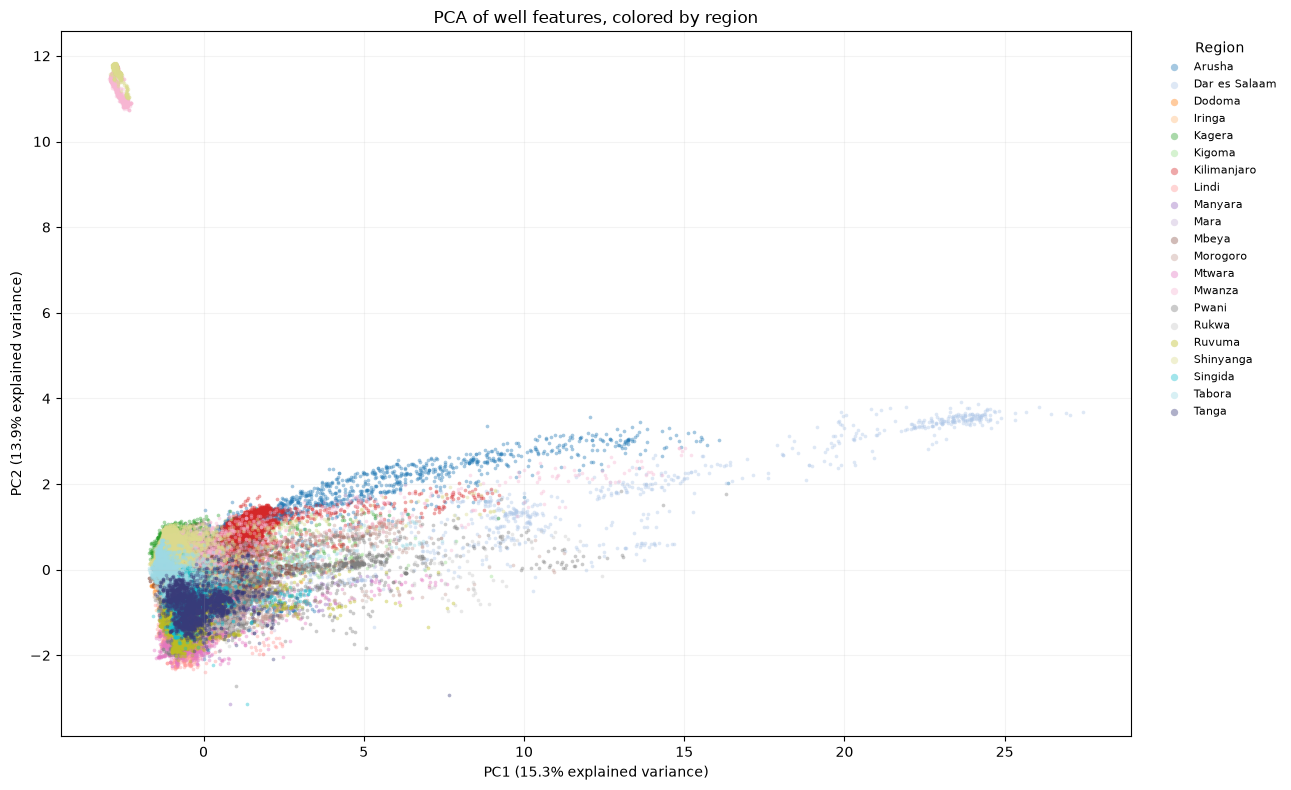

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Region is used only for coloring, never as a PCA input.
# Exclude its numeric code too, along with identifiers and the target label.
pca_features = training_df.drop(columns=["region", "region_code", "id", "status_group"])
region_labels = training_df["region"].fillna("Unknown").astype(str)
numeric_columns = pca_features.select_dtypes(include="number").columns.tolist()
categorical_columns = pca_features.columns.difference(numeric_columns).tolist()
pca_features = pca_features.copy()
# Boolean/mixed categorical fields need consistent string values for encoding.
pca_features[categorical_columns] = (
    pca_features[categorical_columns].fillna("Unknown").astype(str)
)

pca_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ]), numeric_columns),
    ("categorical", OneHotEncoder(
        min_frequency=20, max_categories=50,
        handle_unknown="infrequent_if_exist", sparse_output=False,
    ), categorical_columns),
])
pca_model = Pipeline([
    ("preprocess", pca_preprocessor),
    ("pca", PCA(n_components=2, svd_solver="randomized", random_state=42)),
])
# Fit on the full dataframe for descriptive exploration, not model evaluation.
pca_coordinates = pca_model.fit_transform(pca_features)
pca_df = pd.DataFrame(pca_coordinates, columns=["PC1", "PC2"], index=training_df.index)
pca_df["region"] = region_labels.to_numpy()
pca_df["id"] = training_df["id"].to_numpy()
explained_variance = pca_model.named_steps["pca"].explained_variance_ratio_

fig, ax = plt.subplots(figsize=(13, 8))
regions = sorted(pca_df["region"].unique())
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
for region, color in zip(regions, colors):
    points = pca_df.loc[pca_df["region"].eq(region)]
    ax.scatter(points["PC1"], points["PC2"], color=color, label=region,
               s=7, alpha=0.4, linewidths=0, rasterized=True)
ax.set(
    title="PCA of well features, colored by region",
    xlabel=f"PC1 ({explained_variance[0]:.1%} explained variance)",
    ylabel=f"PC2 ({explained_variance[1]:.1%} explained variance)",
)
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left",
          markerscale=2, frameon=False, fontsize=8)
ax.grid(alpha=0.15)
fig.tight_layout()
print(f"Two components explain {explained_variance.sum():.1%} of transformed feature variance.")
plt.show()


## Region most similar to the other regions
Similarity means the lowest mean Euclidean distance to the other region centroids, using all transformed PCA input features. Regions have equal weight. The PCA view highlights the selected region; the ranking uses the full feature space. This compares average profiles, not complete distributions or within-region variation.

Most similar average region profile: Morogoro


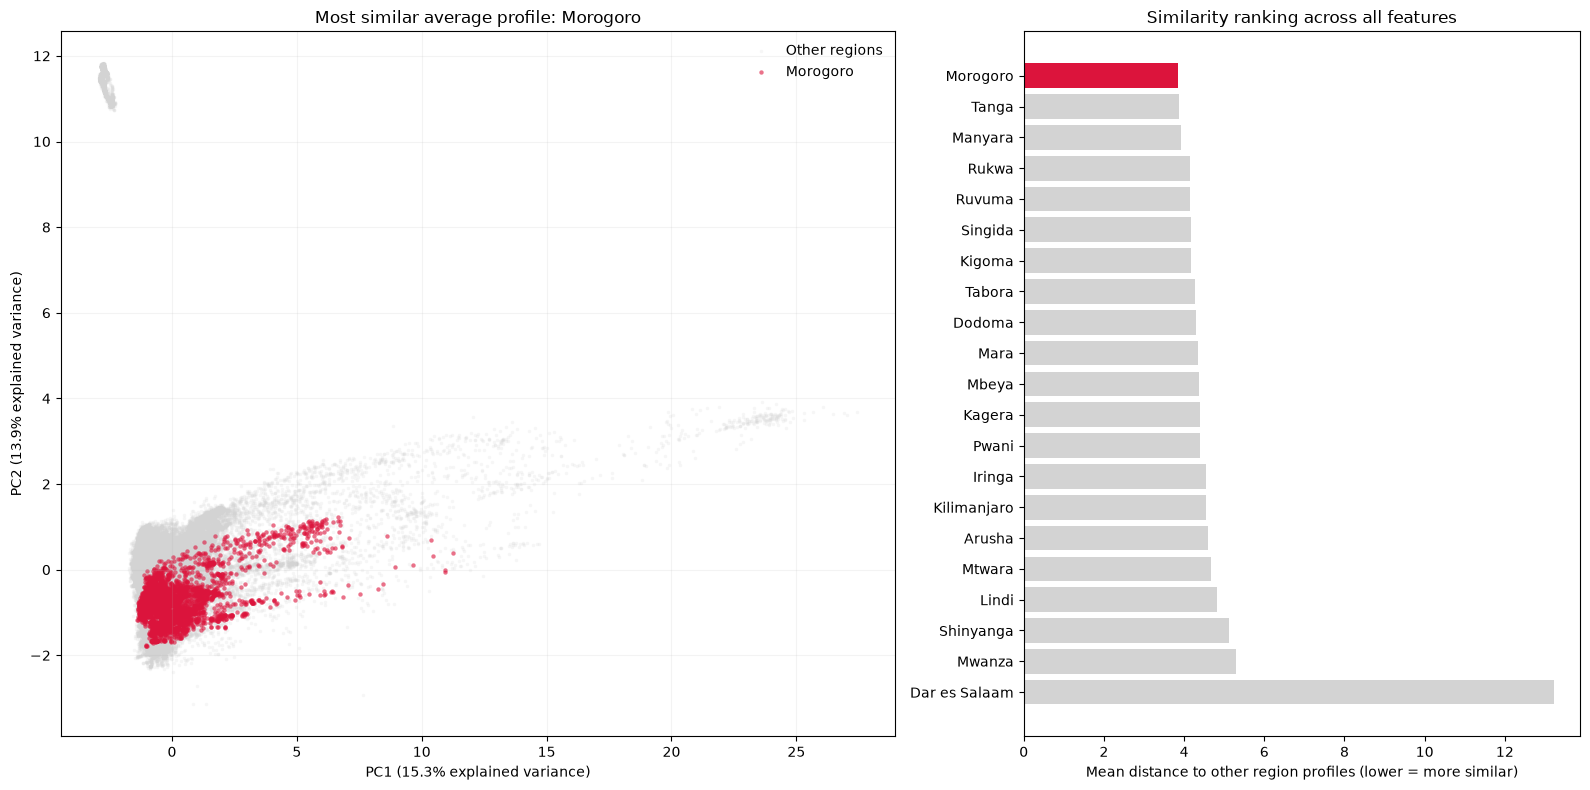

,region,mean_distance_to_other_regions
0,Morogoro,3.84212289
1,Tanga,3.86261351
2,Manyara,3.92348739
3,Rukwa,4.14765082
4,Ruvuma,4.15836784
5,Singida,4.16760931
6,Kigoma,4.17718108
7,Tabora,4.26544146
8,Dodoma,4.28670994
9,Mara,4.33512800


In [111]:
from sklearn.metrics import pairwise_distances

# Compare average region profiles in ALL transformed dimensions, not just PC1/PC2.
# Each region has equal weight, regardless of its number of wells.
similarity_features = pca_model.named_steps["preprocess"].transform(pca_features)
similarity_regions = sorted(pca_df["region"].unique())
region_centroids = np.vstack([
    similarity_features[pca_df["region"].eq(region).to_numpy()].mean(axis=0)
    for region in similarity_regions
])
del similarity_features
region_distance_df = pd.DataFrame(
    pairwise_distances(region_centroids, metric="euclidean"),
    index=similarity_regions, columns=similarity_regions,
)
similarity_df = pd.DataFrame({
    "region": similarity_regions,
    "mean_distance_to_other_regions": (
        region_distance_df.sum(axis=1).to_numpy() / (len(similarity_regions) - 1)
    ),
}).sort_values("mean_distance_to_other_regions").reset_index(drop=True)
most_similar_region = similarity_df.iloc[0]["region"]
highlight = pca_df["region"].eq(most_similar_region)

fig_similarity, (ax_projection, ax_ranking) = plt.subplots(
    1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.5, 1]},
)
ax_projection.scatter(
    pca_df.loc[~highlight, "PC1"], pca_df.loc[~highlight, "PC2"],
    color="lightgray", s=6, alpha=0.2, linewidths=0, label="Other regions", rasterized=True,
)
ax_projection.scatter(
    pca_df.loc[highlight, "PC1"], pca_df.loc[highlight, "PC2"],
    color="crimson", s=10, alpha=0.6, linewidths=0,
    label=most_similar_region, rasterized=True,
)
ax_projection.set(
    title=f"Most similar average profile: {most_similar_region}",
    xlabel=f"PC1 ({explained_variance[0]:.1%} explained variance)",
    ylabel=f"PC2 ({explained_variance[1]:.1%} explained variance)",
)
ax_projection.legend(frameon=False)
ax_projection.grid(alpha=0.15)
ax_ranking.barh(
    similarity_df["region"], similarity_df["mean_distance_to_other_regions"],
    color=["crimson" if region == most_similar_region else "lightgray"
           for region in similarity_df["region"]],
)
ax_ranking.invert_yaxis()
ax_ranking.set(title="Similarity ranking across all features",
               xlabel="Mean distance to other region profiles (lower = more similar)")
fig_similarity.tight_layout()
print(f"Most similar average region profile: {most_similar_region}")
plt.show()
similarity_df


# Nearest well kilometer distance
Using the held-out region set, we can get a clear view of the impact on water access within a geographical area.

In [112]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from water_wells import DataConfig, DataLoader, TrainingConfig, TrainingPipeline, ModelEvaluator

# Load raw features and ID-aligned labels; this cell can run independently.
root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent
X_raw, y = DataLoader(DataConfig(data_dir=root)).load_training()
config = TrainingConfig()  # Usual 500-tree XGBoost settings.
holdout_regions = ["Morogoro"]
pipeline = TrainingPipeline(
    config,
    population_raster=root / "tza_pop_2026_CN_1km_R2025A_UA_v1.tif",
    cache_dir=root / "data/processed/population",
    data_mode="auto",
)

# Reuse/write population sums and save the enriched raw data.
X_model = pipeline.prepare_population_data(
    X_raw, output_path=root / "data/processed/training_population.csv",
)
X_model.assign(status_group=y).to_csv(
    root / "data/processed/training_population_labels.csv", index=False,
)
X_train, X_valid, X_holdout, y_train, y_valid, y_holdout = pipeline.split(
    X_model, y, holdout_regions=holdout_regions,
)

# All training-dependent feature engineering and preprocessing fit on X_train.
pipeline.fit(X_train, y_train)
evaluator = ModelEvaluator()

results_df = pipeline.predict_wells(X_valid)
results_df["actual_status"] = y_valid
results_df["region"] = X_valid["region"]
predictions = results_df["predicted_status"]

# Includes coordinates, readable predictions and probabilities for mapping.
holdout_results_df = pipeline.predict_wells(X_holdout)
holdout_results_df["actual_status"] = y_holdout
holdout_results_df["region"] = X_holdout["region"]
holdout_predictions = holdout_results_df["predicted_status"]

# Probability predictions are already computed by predict_wells above.
# Keep identifiers and coordinates alongside the three class probabilities.
probability_columns = [
    "id", "latitude", "longitude", "region",
    "probability_functional", "probability_needs_repair", "probability_non_functional",
]
validation_probabilities_df = results_df[probability_columns].copy()
holdout_probabilities_df = holdout_results_df[probability_columns].copy()

# Optional evaluation displays:
# metrics_df = pd.DataFrame.from_dict({
#     "validation": evaluator.metrics(y_valid, predictions),
#     "geographic_holdout": evaluator.metrics(y_holdout, holdout_predictions),
# }, orient="index")
# print(f"Train: {len(X_train):,}; validation: {len(X_valid):,}; holdout: {len(X_holdout):,}")
# display(metrics_df)
# print("Geographic holdout classification report:")
# print(evaluator.classification_report(y_holdout, holdout_predictions))
# display(holdout_results_df.head())
# display(evaluator.confusion_matrix(y_holdout, holdout_predictions))

# Final output: per-well probabilities for the unseen region.
holdout_probabilities_df


,id,latitude,longitude,region,probability_functional,probability_needs_repair,probability_non_functional
70,21990,-8.93495018,35.81898147,Morogoro,0.48950890,0.03448981,0.47600132
81,65531,-7.02426273,37.72295310,Morogoro,0.53870630,0.07157809,0.38971561
116,21068,-6.82950072,37.48747402,Morogoro,0.45333737,0.03141353,0.51524913
141,60852,-6.77169870,37.82346185,Morogoro,0.68190587,0.05747630,0.26061788
143,17687,-6.29976667,37.44310991,Morogoro,0.11760443,0.02029107,0.86210454
...,...,...,...,...,...,...,...
59292,6602,-6.11143014,37.64362707,Morogoro,0.62603134,0.03555956,0.33840910
59316,10273,-6.33154845,37.42306002,Morogoro,0.38662338,0.04326852,0.57010812
59353,45533,-7.01473202,37.72815776,Morogoro,0.59718442,0.04264452,0.36017105
59394,11164,-6.12482968,37.63405278,Morogoro,0.69378358,0.03316080,0.27305564


Average precision: 0.797
Nonfunctional wells: 1,587 / 4,006


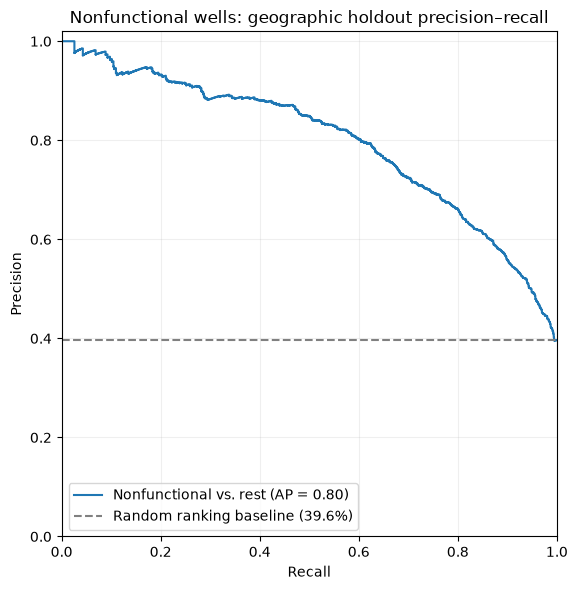

In [113]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

# One-vs-rest: "non functional" is positive; the other two statuses are negative.
# Use ground-truth labels and continuous probabilities, not predicted classes.
nonfunctional_actual = holdout_results_df["actual_status"].eq("non functional")
nonfunctional_probability = holdout_results_df["probability_non_functional"]
nonfunctional_ap = average_precision_score(nonfunctional_actual, nonfunctional_probability)
nonfunctional_prevalence = nonfunctional_actual.mean()

fig_pr, ax_pr = plt.subplots(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(
    nonfunctional_actual, nonfunctional_probability,
    name="Nonfunctional vs. rest", ax=ax_pr,
)
ax_pr.axhline(
    nonfunctional_prevalence, color="gray", linestyle="--",
    label=f"Random ranking baseline ({nonfunctional_prevalence:.1%})",
)
ax_pr.set(title="Nonfunctional wells: geographic holdout precision–recall",
          xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax_pr.grid(alpha=0.2)
ax_pr.legend(loc="lower left")
fig_pr.tight_layout()
print(f"Average precision: {nonfunctional_ap:.3f}")
print(f"Nonfunctional wells: {nonfunctional_actual.sum():,} / {len(nonfunctional_actual):,}")
plt.show()


In [114]:
import numpy as np
from sklearn.neighbors import BallTree
from rasterio.warp import transform as transform_coordinates

# Keep population pixels within this distance of ANY holdout well.
nearby_radius_m = 5_000  # Adjust the definition of "nearby" here.

holdout_tree = BallTree(
    np.radians(X_holdout[["latitude", "longitude"]].to_numpy()),
    metric="haversine",
)
pop_longitude, pop_latitude = transform_coordinates(
    pop_tanzania.crs, "EPSG:4326",
    population_df["x"].to_numpy(), population_df["y"].to_numpy(),
)
nearest_distance, _ = holdout_tree.query(
    np.radians(np.column_stack([pop_latitude, pop_longitude])), k=1,
)
nearby_mask = nearest_distance[:, 0] * 6_371_000 <= nearby_radius_m

# Same columns as population_df: x, y, population. Preserve the original.
# No filtering by predicted/actual well status at this stage.
# Distance to the nearest FUNCTIONAL well will be added separately later.
filtered_population_df = population_df.loc[nearby_mask, ["x", "y", "population"]].copy()
filtered_population_df


,x,y,population
310269,37.48749913,-5.77916631,0.00000000
310270,37.49583246,-5.77916631,0.00000000
310271,37.50416580,-5.77916631,0.73343247
310272,37.51249913,-5.77916631,6.43790150
310273,37.52083246,-5.77916631,2.85223436
...,...,...,...
543543,36.02916580,-9.22083296,7.94287682
543986,35.98749914,-9.22916629,0.00000000
543987,35.99583247,-9.22916629,0.90022510
543988,36.01249914,-9.22916629,7.21427679


In [115]:
import numpy as np
from sklearn.neighbors import BallTree
from rasterio.warp import transform as transform_coordinates

# Scenario: correctly identified nonfunctional wells are assumed repaired.
# Wells needing repair do not qualify unless the rule is changed explicitly.
functional_wells_df = holdout_results_df.loc[
    holdout_results_df["actual_status"].eq("functional")
    | (
        holdout_results_df["actual_status"].eq("non functional")
        & holdout_results_df["predicted_status"].eq("non functional")
    )
].copy()
functional_tree = BallTree(
    np.radians(functional_wells_df[["latitude", "longitude"]].to_numpy()),
    metric="haversine",
)
filtered_longitude, filtered_latitude = transform_coordinates(
    pop_tanzania.crs, "EPSG:4326",
    filtered_population_df["x"].to_numpy(), filtered_population_df["y"].to_numpy(),
)
functional_distance, functional_position = functional_tree.query(
    np.radians(np.column_stack([filtered_latitude, filtered_longitude])), k=1,
)

# Use the actual well ID, not its dataframe index or tree position.
filtered_population_df["nearest_functional_well_id"] = (
    functional_wells_df["id"].to_numpy()[functional_position[:, 0]]
)
filtered_population_df["distance_to_nearest_functional_well_m"] = (
    functional_distance[:, 0] * 6_371_000
)
# Baseline access: only wells that are already functional in the ground truth.
already_functional_wells_df = holdout_results_df.loc[
    holdout_results_df["actual_status"].eq("functional")
]
baseline_functional_tree = BallTree(
    np.radians(already_functional_wells_df[["latitude", "longitude"]].to_numpy()),
    metric="haversine",
)
baseline_functional_distance, _ = baseline_functional_tree.query(
    np.radians(np.column_stack([filtered_latitude, filtered_longitude])), k=1,
)
filtered_population_df["distance_to_nearest_functional_well_without_intervention_m"] = (
    baseline_functional_distance[:, 0] * 6_371_000
)
filtered_population_df


,x,y,population,nearest_functional_well_id,distance_to_nearest_functional_well_m,distance_to_nearest_functional_well_without_intervention_m
310269,37.48749913,-5.77916631,0.00000000,1698,4559.40756176,11692.67014459
310270,37.49583246,-5.77916631,0.00000000,1698,4286.10921413,11776.81339394
310271,37.50416580,-5.77916631,0.73343247,1698,4201.54815127,11931.79234570
310272,37.51249913,-5.77916631,6.43790150,1698,4316.83000943,12154.89776611
310273,37.52083246,-5.77916631,2.85223436,1698,4617.00937663,12442.46547456
...,...,...,...,...,...,...
543543,36.02916580,-9.22083296,7.94287682,41718,4442.86144395,4442.86144395
543986,35.98749914,-9.22916629,0.00000000,25838,4369.57951404,4369.57951404
543987,35.99583247,-9.22916629,0.90022510,25838,4207.64104888,4207.64104888
543988,36.01249914,-9.22916629,7.21427679,25838,4466.10491352,4466.10491352


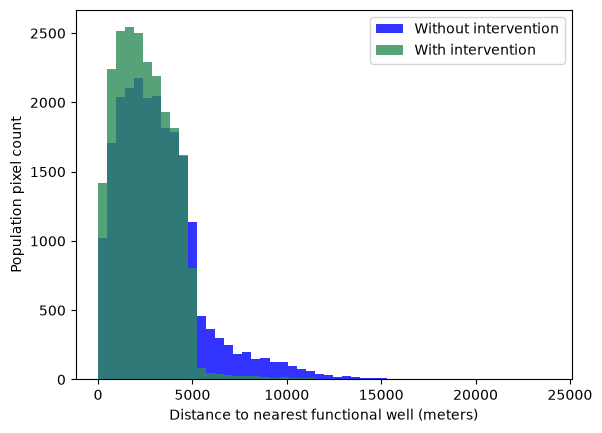

In [133]:
plt.hist(
    [filtered_population_df[column].dropna() for column in columns],
    bins=50,
    histtype='stepfilled',
    color=["seagreen", "blue"],
    alpha=0.8,
    label=["With intervention", "Without intervention"],
)
plt.xlabel("Distance to nearest functional well (meters)")
plt.ylabel("Population pixel count")
plt.legend()
plt.show()

np.float32(3.2868882e+06)

In [117]:
X_holdout[['id', 'longitude', 'latitude']].set_index('id')[]

SyntaxError: invalid syntax (965237468.py, line 1)

In [150]:
import numpy as np
from sklearn.neighbors import BallTree
from rasterio.warp import transform as transform_coordinates

def build_population_access_df(population_df, holdout_results_df,
                               population_crs="EPSG:4326", nearby_radius_m=5_000):
    """Filter population pixels and add nearest-well access distances in meters.

    Intervention assumes successful repair of correctly predicted nonfunctional
    wells. Baseline uses only actual functional wells. Inputs are unchanged.
    """
    earth_radius_m = 6_371_000
    # 1. Keep population pixels near any holdout well, regardless of status.
    pop_longitude, pop_latitude = transform_coordinates(
        population_crs, "EPSG:4326",
        population_df["x"].to_numpy(), population_df["y"].to_numpy(),
    )
    pop_coordinates = np.radians(np.column_stack([pop_latitude, pop_longitude]))
    holdout_tree = BallTree(
        np.radians(holdout_results_df[["latitude", "longitude"]].to_numpy()),
        metric="haversine",
    )
    nearest_distance, _ = holdout_tree.query(pop_coordinates, k=1)
    nearby_mask = nearest_distance[:, 0] * earth_radius_m <= nearby_radius_m
    filtered_population_df = population_df.loc[nearby_mask, ["x", "y", "population"]].copy()
    filtered_coordinates = pop_coordinates[nearby_mask]

    # 2. Intervention scenario: existing functional wells plus correctly predicted
    # nonfunctional wells, which are assumed successfully repaired.
    functional_wells_df = holdout_results_df.loc[
        holdout_results_df["actual_status"].eq("functional")
        | (
            holdout_results_df["actual_status"].eq("non functional")
            & holdout_results_df["predicted_status"].eq("non functional")
        )
    ].copy()
    functional_tree = BallTree(
        np.radians(functional_wells_df[["latitude", "longitude"]].to_numpy()),
        metric="haversine",
    )
    functional_distance, functional_position = functional_tree.query(filtered_coordinates, k=1)
    filtered_population_df["nearest_functional_well_id"] = (
        functional_wells_df["id"].to_numpy()[functional_position[:, 0]]
    )
    filtered_population_df["distance_to_nearest_functional_well_m"] = (
        functional_distance[:, 0] * earth_radius_m
    )

    # 3. Without intervention: only ground-truth functional wells qualify.
    already_functional_wells_df = holdout_results_df.loc[
        holdout_results_df["actual_status"].eq("functional")
    ]
    baseline_functional_tree = BallTree(
        np.radians(already_functional_wells_df[["latitude", "longitude"]].to_numpy()),
        metric="haversine",
    )
    baseline_functional_distance, _ = baseline_functional_tree.query(filtered_coordinates, k=1)
    filtered_population_df["distance_to_nearest_functional_well_without_intervention_m"] = (
        baseline_functional_distance[:, 0] * earth_radius_m
    )
    return filtered_population_df


filtered_population_df = build_population_access_df(
    population_df,
    holdout_results_df,
    population_crs=pop_tanzania.crs,
    nearby_radius_m=2_500,
)
filtered_population_df


,x,y,population,nearest_functional_well_id,distance_to_nearest_functional_well_m,distance_to_nearest_functional_well_without_intervention_m
311662,37.49583246,-5.79583297,1.30387628,1698,2496.89404491,9942.23318715
312376,37.48749913,-5.80416631,0.48895565,1698,2271.47747587,8917.76439031
312377,37.49583246,-5.80416631,5.54888868,1698,1655.97462144,9027.80330238
312378,37.50416580,-5.80416631,293.95062256,1698,1422.86978621,9229.05216464
312379,37.51249913,-5.80416631,363.70233154,1698,1733.93464941,9515.72571556
...,...,...,...,...,...,...
542186,36.02083247,-9.19583296,2.37536526,41718,1834.95399852,1834.95399852
542631,36.00416580,-9.20416629,49.37349701,25838,1543.74375342,1543.74375342
542632,36.01249914,-9.20416629,88.86520386,41718,1930.96181544,1930.96181544
542633,36.02083247,-9.20416629,81.00147247,41718,2417.47388776,2417.47388776


,index,x,y,population,nearest_functional_well_id,distance_to_nearest_functional_well_m,distance_to_nearest_functional_well_without_intervention_m
0,311662,37.49583246,-5.79583297,1.30387628,1698,2496.89404491,9942.23318715
1,312376,37.48749913,-5.80416631,0.48895565,1698,2271.47747587,8917.76439031
2,312377,37.49583246,-5.80416631,5.54888868,1698,1655.97462144,9027.80330238
3,312378,37.50416580,-5.80416631,293.95062256,1698,1422.86978621,9229.05216464
4,312379,37.51249913,-5.80416631,363.70233154,1698,1733.93464941,9515.72571556
...,...,...,...,...,...,...,...
12175,542186,36.02083247,-9.19583296,2.37536526,41718,1834.95399852,1834.95399852
12176,542631,36.00416580,-9.20416629,49.37349701,25838,1543.74375342,1543.74375342
12177,542632,36.01249914,-9.20416629,88.86520386,41718,1930.96181544,1930.96181544
12178,542633,36.02083247,-9.20416629,81.00147247,41718,2417.47388776,2417.47388776


# Water access KPI

In [ ]:
filtered_population_df[['distance_to_nearest_functional_well_m', 'distance_to_nearest_functional_well_without_intervention_m']].max(axis=0)

distance_to_nearest_functional_well_m                        11606.91819148
distance_to_nearest_functional_well_without_intervention_m   21216.58059578
dtype: float64

In [176]:
pop_no_access = (filtered_population_df[['distance_to_nearest_functional_well_m', 'distance_to_nearest_functional_well_without_intervention_m']] > 2500).astype(int)
pop_no_access['population'] = filtered_population_df['population']

pop_no_access.apply(
    lambda row : row[['distance_to_nearest_functional_well_m', 'distance_to_nearest_functional_well_without_intervention_m']].apply(
        lambda val : val * row['population']),
    axis = 1
).sum()

distance_to_nearest_functional_well_m                         43724.79029042
distance_to_nearest_functional_well_without_intervention_m   287942.83531837
dtype: float64

# Using real code implementation

In [177]:
import pandas as pd
from IPython.display import display
from water_wells.kpi_metrics import build_population_access_df, calculate_access_kpis

# Inputs from the TIFF-loading and holdout-prediction cells above.
nearby_radius_m = 2_500
access_distance_m = 2_500

filtered_population_df = build_population_access_df(
    population_df=population_df,
    holdout_results_df=holdout_results_df,
    population_crs=pop_tanzania.crs,
    nearby_radius_m=nearby_radius_m,
)
# Coordinates, population, nearest well IDs, and distances before/after intervention.
display(filtered_population_df.head())

access_kpis = calculate_access_kpis(
    filtered_population_df,
    access_distance_m=access_distance_m,
)
access_kpis_df = pd.Series(access_kpis, name="value").to_frame()
display(access_kpis_df)

print(f"Potential population gaining access: {access_kpis['population_gaining_access']:,.0f}")
print(f"Coverage before intervention: {access_kpis['coverage_before_pct']:.1f}%")
print(f"Coverage after intervention: {access_kpis['coverage_after_pct']:.1f}%")
print(f"Coverage improvement: {access_kpis['coverage_improvement_pp']:.1f} percentage points")


,x,y,population,nearest_functional_well_id,distance_to_nearest_functional_well_m,nearest_functional_well_without_intervention_id,distance_to_nearest_functional_well_without_intervention_m
311662,37.49583246,-5.79583297,1.30387628,1698,2496.89404491,54433,9942.23318715
312376,37.48749913,-5.80416631,0.48895565,1698,2271.47747587,54433,8917.76439031
312377,37.49583246,-5.80416631,5.54888868,1698,1655.97462144,54433,9027.80330238
312378,37.50416580,-5.80416631,293.95062256,1698,1422.86978621,54433,9229.05216464
312379,37.51249913,-5.80416631,363.70233154,1698,1733.93464941,54433,9515.72571556


,value
population_total,2666507.46692222
population_with_access_before,2378564.63160385
population_without_access_before,287942.83531837
population_with_access_after,2622782.67663180
population_without_access_after,43724.79029042
population_gaining_access,244218.04502795
coverage_before_pct,89.20149901
coverage_after_pct,98.36022247
coverage_improvement_pp,9.15872346


Potential population gaining access: 244,218
Coverage before intervention: 89.2%
Coverage after intervention: 98.4%
Coverage improvement: 9.2 percentage points


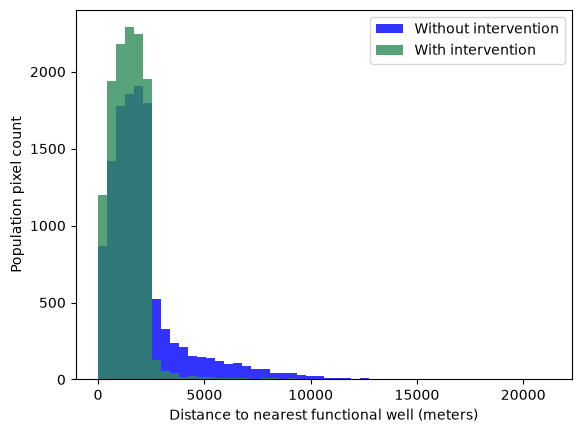

In [180]:
plt.hist(
    [filtered_population_df[column].dropna() for column in columns],
    bins=50,
    histtype='stepfilled',
    color=["seagreen", "blue"],
    alpha=0.8,
    label=["With intervention", "Without intervention"],
)
plt.xlabel("Distance to nearest functional well (meters)")
plt.ylabel("Population pixel count")
plt.legend()
plt.show()